In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import neurokit2 as nk
import cvxeda
from eda_proj.nn_gms import *

In [2]:
wesad_data = pd.read_csv("../Data/wesad_eda/filtered_eda_signals.csv")
wesad_data.iloc[0:6,0]

0    0.000000
1    0.073305
2    0.116746
3    0.083819
4    0.062718
5    0.079352
Name: S15_EDA, dtype: float64

In [3]:
sig = wesad_data.iloc[:, 0]

## Using CVXEda

In [4]:
r, p, t, l, d, e, obj = cvxeda.cvxEDA(sig, 1.0 / 4, options={"show_progress": False}
)


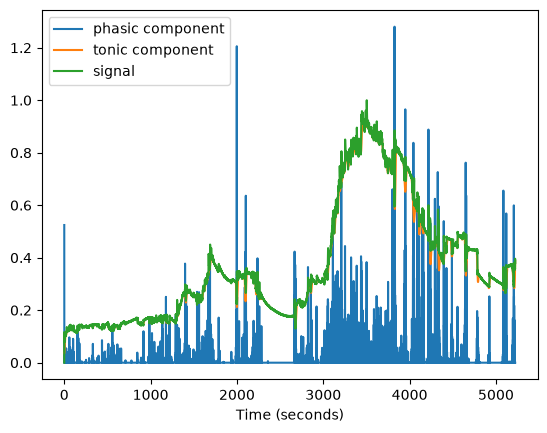

In [5]:
time = np.arange(len(p)) / 4

plt.plot(time, p, label='phasic component')
plt.plot(time, t, label='tonic component')
plt.plot(time, sig, label='signal')
plt.xlabel('Time (seconds)')
plt.legend()
plt.show()

## Using neurokit

In [6]:
type(sig)

pandas.core.series.Series

In [7]:
signals, info = nk.eda_process(np.array(sig), sampling_rate=4)
signals['SCR_Amplitude']

/opt/anaconda3/envs/py314/lib/python3.14/site-packages/neurokit2/eda/eda_clean.py:102: NeuroKitWarning: EDA signal is sampled at very low frequency. Skipping filtering.
  warn(


0        0.000000
1        0.000000
2             NaN
3        0.000000
4        0.000000
           ...   
20887    0.000000
20888    0.000000
20889    0.033234
20890    0.000000
20891    0.000000
Name: SCR_Amplitude, Length: 20892, dtype: float64

In [8]:
signals.columns

Index(['EDA_Raw', 'EDA_Clean', 'EDA_Tonic', 'EDA_Phasic', 'SCR_Onsets',
       'SCR_Peaks', 'SCR_Height', 'SCR_Amplitude', 'SCR_RiseTime',
       'SCR_Recovery', 'SCR_RecoveryTime'],
      dtype='object')

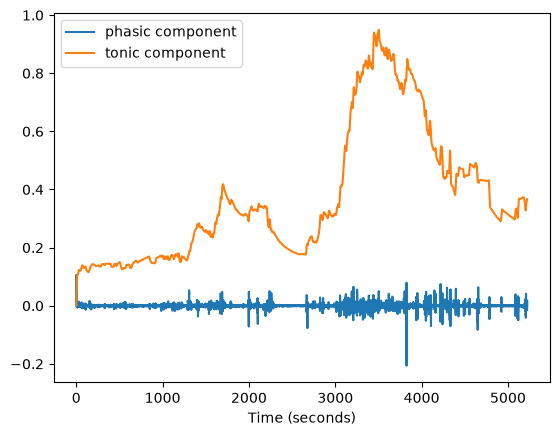

In [9]:
plt.plot(time, signals['EDA_Phasic'], label='phasic component')
plt.plot(time, signals['EDA_Tonic'], label='tonic component')
#plt.plot(time, signals['SCR_Amplitude'], label='amp')
#plt.plot(time, sig, label='signal')
plt.xlabel('Time (seconds)')
plt.legend()
plt.show()

## Using NN_GMS

In [10]:
sig = np.array(sig)
Y = chop_data(sig, 30, 0.5)
Y.shape

(697, 59)

In [11]:
sig1 = sig[:240]
Y = chop_data(sig1, 5, 0.8)
Y.shape

(48, 21)

In [12]:
num_chops = 30
overlap = 0.5
phasec, tonic = nn_gmsEDA(sig, 4, num_chops, overlap)

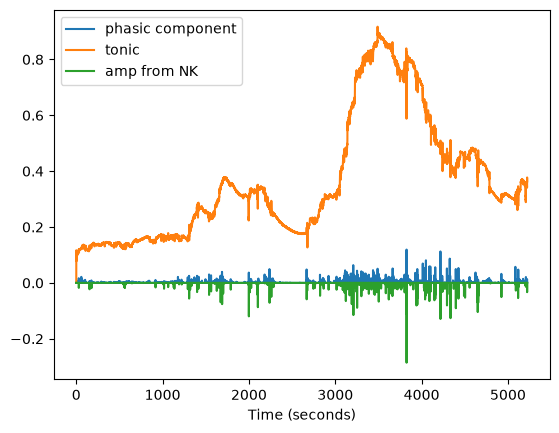

In [13]:
time = np.arange(len(phasec))/4
plt.plot(time, phasec, label='phasic component')
plt.plot(time, tonic, label = 'tonic')
plt.plot(time, -signals['SCR_Amplitude'], label = 'amp from NK')
#plt.plot(time, sig, label='signal')
plt.xlabel('Time (seconds)')
plt.legend()
plt.show()

In [14]:
num_chops = 30
overlap = 0.5
phasic_con, tonic_con = nn_gmsEDA_con(sig, 4, num_chops, overlap)

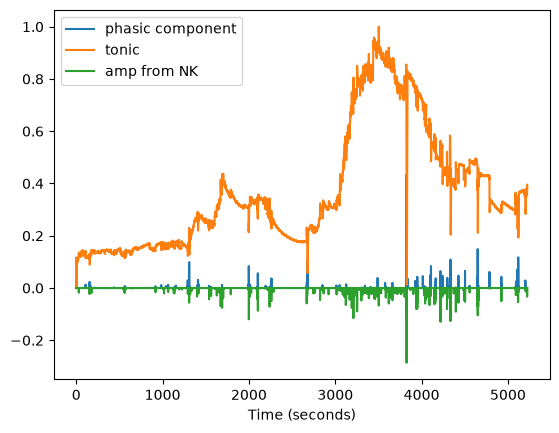

In [17]:
time = np.arange(len(phasic_con))/4
plt.plot(time, phasic_con, label='phasic component')
plt.plot(time, tonic_con, label = 'tonic')
plt.plot(time, -signals['SCR_Amplitude'], label = 'amp from NK')
#plt.plot(time, sig, label='signal')
plt.xlabel('Time (seconds)')
plt.legend()
plt.show()